                        Informe de la etapa 1

se carga el archivo JSON de satelites, observando la totalidad de los registros hechos y sus caracteristicas.

In [ ]:
from catalogo import leer_satelites, contar_por_grupo, lanzamientos_por_anio
from satelite import __str__, crear_satelites
from datetime import datetime
import analisis

ruta = "datos/satelites.json"
registros = leer_satelites(ruta)
print("registro total:", len(registros))
epoch= registros[0].get('EPOCH')
print("fecha de los datos 'EPOCH':", epoch)
actual= datetime.now()
l_satelites= crear_satelites(registros, actual)
descartados= len(registros) - len(l_satelites)
print("los satelites descartados por crear_satelites:", descartados)


se agruparon los satelites segun su informacion para saber su distribucion y ademas para poder calcular el porcentaje de los satelites Starlink

In [ ]:

conteo_grupos= contar_por_grupo(registros)
print("satelites por grupo:")
for grupo, cantidad in conteo_grupos.items():
    print(f'{grupo} : {cantidad}')

cant_starlink= conteo_grupos.get("Starlink", 0)
procentaje_strlink= (cant_starlink / len(registros)) * 100 if len (registros) > 0 else 0
print("el porcentaje total de Starlink", procentaje_strlink)


a partir de identificarlos, se evaluo la cantidad de satelites lanzados desde 2015 para saber el año con mas lanzamientos que hubo

In [ ]:
print("lanzamineto por año:")
        
anio_max= ""
max_cant= 0

dts_anios= lanzamientos_por_anio(registros)

for anio in sorted(dts_anios):
    if int(anio) >= 2015:
        cantidad = dts_anios[anio]
        print(f" año {anio} : {cantidad}")
        if cantidad > max_cant:
            max_cant = cantidad
            anio_max = anio

print()

se clasifican los satelites segun su regimen ortbital(LEO, MEO, GEO, HEO) utilizando las altitudes actuales

In [ ]:
momento_actual= datetime.now()

l_satelites= crear_satelites(registros, momento_actual)
print(f"se crearon {len(l_satelites)} satelites validos")

tipos_orbita= analisis.contar_por_tipo(l_satelites)
print("agrupacion segun el tipo de orbita:")
for orbita, cant in tipos_orbita.items():
    print(f"{orbita} : {cant}")

se identifica los satelites de mayor y menor altitud, para hacer luego un top 10 de cada uno

In [ ]:

alto = analisis.mas_alto(l_satelites)
bajo = analisis.mas_bajo(l_satelites)
print("satelite mas alto:", alto)
print("satelite mas bajo:", bajo)

def obtener_altitud(satelite):
    return satelite.altitud

top_altos= sorted(l_satelites, key=obtener_altitud, reverse=True)
for i in range(min(10, len(top_altos))):
    print("top de 10 altos:")
    print(top_altos[i])

top_bajos= sorted(l_satelites, key=obtener_altitud)
for i in range(min(10, len(top_bajos))):
    print("top de 10 bajos:")
    print(top_bajos[i])


se genera un resumen de las altitudes (cantidad, minmia, maxima y media)

In [ ]:
resumen_g= {
    "LEO": [],
    "MEO": [],
    "GEO": [],
    "HEO": []
}

for satelite in l_satelites:
    tipo = satelite.tipo_orbita()
    if tipo in resumen_g:
        resumen_g[tipo].append(satelite.altitud)

for grupo, altitudes in resumen_g.items():
    cantidad = len(altitudes)
    if cantidad > 0:
        minima= min(altitudes)
        maxima= max(altitudes)
        promedio= sum(altitudes)/ cantidad
    else:
        minima= 0
        maxima= 0
        promedio= 0

print("cantidad:", cantidad)
print("altitud maxima:", maxima)
print("altitud minima", minima)
print("promedio:", promedio)



se filtra unicamente el satelite que este en dentro de las coordenadas (sacada de internet) sobre la zona de bariloche 

In [ ]:
zona_bariloche = (-76.30, -46.13, -66.30, -36.13) 
satelites_bariloche= []
for satelite in l_satelites:
    if satelite.esta_en_zona(zona_bariloche):
        satelites_bariloche.append(satelite)

bariloche_ord= sorted(satelites_bariloche, key= obtener_altitud)
for sat in bariloche_ord:
    print(sat)

Conslusiones:

a lo largo de este proceso, se filtro y analizo por completo los satelites de 'satelites.json', para haber obtenido:

-las clasificaciones y distribuciones de los satelites 
-a partir de los los lanzamientos registrados, se observo la actividad de los ultimos años (desde el 2015)
-mediante el metodo de 'esta_en_zona' junto con las funciones de ordeamiento y el '__str__', fue posible visualizar especificamente un satelite en la region de bariloche.

                                    ETAPA 2

Lanzamiento en el tiempo:
 

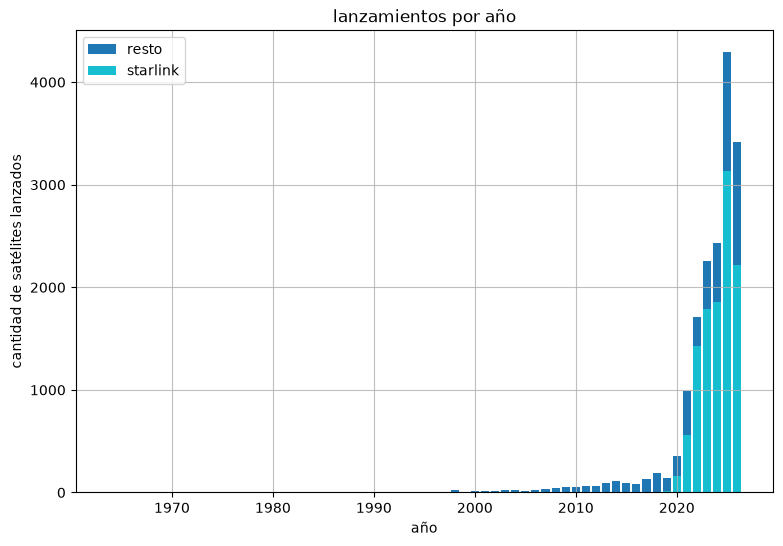

In [72]:
import matplotlib.pyplot as plt

registro_starlink= [i for i in registros if "starlink" in str(i.get("OBJECT_NAME", "")).lower()]
registro_resto= [r for r in registros if "starlink" not in str(r)]

datos_s= lanzamientos_por_anio(registro_starlink)
datos_r= lanzamientos_por_anio(registro_resto)

totales= sorted(list(set(list(datos_s.keys())+ list(datos_r.keys()))), key= int)
cant_s=[datos_s.get(anio, 0) for anio in totales]
cant_r=[datos_r.get(anio, 0) for anio in totales]

plt.figure(figsize=(9,6))
plt.grid(alpha=0.8)
plt.bar(totales, cant_r, label= "resto", color= "C0")
plt.bar(totales, cant_s, label= "starlink", color= "C9")
plt.title("lanzamientos por año")
plt.xlabel("año")
plt.ylabel("cantidad de satélites lanzados")
plt.legend()
plt.show()

grafico

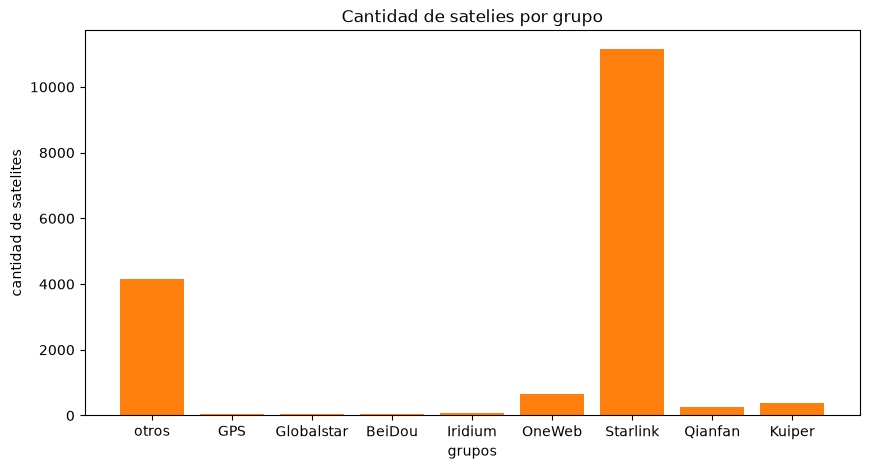

In [73]:

resumen_grupos= contar_por_grupo(registros)

gruposs= list(resumen_grupos.keys())
cantidades= list(resumen_grupos.values())

plt.figure(figsize=(10,5))
plt.bar(gruposs, cantidades, color="C1")
plt.title("Cantidad de satelies por grupo")
plt.xlabel("grupos")
plt.ylabel("cantidad de satelites")
plt.show()

